# Lab02. Токены, поиск и внимание
Полный прогон на GPU Colab: 1500 слияний собственного BPE, 500 абзацев и 12 запросов. Модели заморожены. На локальном компьютере этот ноутбук не выполняем.

## 1. Проверяем облачную GPU
Проверка останавливает выполнение до загрузки моделей, если выбрана локальная среда или нет GPU.

In [15]:
import os, sys, subprocess
from pathlib import Path
if not os.environ.get("COLAB_RELEASE_TAG") or not Path("/content").is_dir():
    raise RuntimeError("Запускайте только в облачном Google Colab")
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Выберите GPU в настройках Colab")
print("GPU:", torch.cuda.get_device_name(0), "PyTorch:", torch.__version__)

GPU: Tesla T4 PyTorch: 2.14.1+cu130


## 2. Восстанавливаем исходники
Встроенный архив содержит только код. SHA256 проверяет, что запускается именно подготовленный вариант. Книга и модели скачиваются в Colab.

In [16]:
import base64, hashlib, io, json, zipfile
WORK = Path("/content/mtusi-lab02")
WORK.mkdir(exist_ok=True)
MANIFEST = {'lab02/run.py': 'b7e09fedbc26fbae0ded4c85d0062dbaac09568b4f1fea5893781d45477bf98d', 'lab02/queries.json': '130156b3e18390b0c1dba161764099872bc2847c4bd5f020f7704d04fbdedb33', 'lab02/requirements.txt': '7de588ac8e6ff4632c8e38c0fc734654705bbdd8ba4edbcd5a39017a53f5f51b', 'pt01/run.py': 'f4a88e10fe73f7e262ffa588b339ffe743e1f99edca975e81ae82b8067c7a10a'}
BUNDLE = 'UEsDBBQAAAAIAGStal1vzBd1FBcAAJs9AAAMAAAAbGFiMDIvcnVuLnB5rVvdj9zWdX/fv+J2jYKkNEvNrHZXq1VoRJbXtVBXViQ5eZhOCQ55Z4YZDkmTnP2wsEDstHEBBzAatEBRoGnRh770RVGsWLFsBfBfMPsf5XfuB7+Guyu3FaCdIe+955x77vm+ZzY3Nz/wxv3tA/bOw8MeK5I5j9l4GUx5kfdY6mXeNPPSGct4kYX8yIuYFwfMKwoeF2ES2xsb7y2jiC2SgEcsjCc847HP2ZhHSTzNWRKze0nkjdkN5gHGIik4y5ZxzLMei/kRz1gx4yxKfACOvLRIUntjc3NzY5IlC+a6k2WxzLjrsnCRJlkB3HFSeIQ439jQ77IpyMy5XOMnUcR9MUMvupcs44JncnyyjP0iSaJyNMqWru/5M67hTX39beblsygc68ef50ksgaReQQMaxEM86klp5BWTJFvo5/w011+LcME3Nt4/fHTIHLHGxAbDCNuz7IznSXTETcvGXsDajUcffvgE02i2fgVQNmG2wzjnWWH2eywvMpNmWpYirOgPbPC33FziBa6fZOkyV2cbfsLd4yQL8EynufQK7o5T0PWTnx0+AELjJ8c8vkF/bm717b13tt7xcm5sHO7SWBgXE4AsbiyWURFGYTxdetEW393KF14UGRuPDn96//H9Dx88xuSnBPCAGYG3f2s8Ge/19/3BzviWP9nuj72Bz3cG2/u3+H7Ad27v+X0/MHobrP7vcBeL9wY72zuDyd729mT3pr/D+WRye/92fxz4O5ObA3/CfX9nsD++aZxtPD588OTwwT3irbH6zfkvVs/OP2er1+efrr7F38/w4sXqFVv9Ce9/tXqJh+/OP1s9Y6uXDFO+WT1bfY3/r3rs/HO8f80w4ff08Wz1Hb3Hiq/Pv2D0joZXz8+/sI2N+w8eP3n00b0n2LJA+1uMPV+9OP8cS/7IxMRX578G9NeE+PXW+S/Of3n+qcD3kjCvnjMaBCm/Wr1ggoo/rL7CC4H6tYJGZGIVPoD210TuK6KApvzb6rerf1/9y+q/Qczhg7/64P7j90GIaTyBUqVZSJo48wJoI5S68KI5ToxBOpkXLZKc1InNkiVUkXSaFHG65HmRs2NoMZtmyTHNL8KMBzYz6sdj3I1jD9IFiSJjINb60OJ5j77G+hXWB8lx852YxrypF8ZtoA+ScRKcsgDiDnISFnHviEwJKOZi7QxEV8TSEwvCgMEmsJzzBa3B99CXs0nfCCtEc418zM+OvLhg4yxZTmcgjXsVZD+JYZpyYWgYLFDMAwzCZBCwY+80F2hDjM0AHyzMea+FAaQIDniZhCof+SLlWZLZhrWxsRHwCcuxQ5cMi0ma3cPeC886EJCEqh9nIRS04CeFSbPsYLlIc5NmQX/jnIyjl/th6LznRUQEGA5T4Wxb7Doz/jY2aJafBDhHx1gWk619gfnHpdEzF95JDpvgDCxBz8dQfFcbisxUpAjbUmRenJNpA2e0fbm7LJIneraYCj8BfjUHbFrvpuRCcOo8MMk09DD1KMzBYac0G0MaGGne+GS3JTG5SSw4IHtnsa23sc3ioI4u4rHZJl0swbEFgZun3A+9SMGSvLKGMGfpsnDDIDdKnDkn7+GWfq+GuMeicBHiO5ALIqIwL4ZB6BcjSYtcC9F12DC1sSJMTUuoWypkBYDsPI3CAoaT5xgKJ2ynz37kCPKb1tlMLYtGBtv9UX2jw6dGGBigAfJGAPE1PRM48Eag4fESJwSzbmp6hgeC8JE10ptMvdhNkzwUbtJMJpNcePu88LKCJCawGtwdhhqDGfEJZmQhVMZqYlNQxK5oFvsRARLCL6aztyV8TcTCy2E83AX3YnMWBhDbnninUL/F7vr+En4GsAmR8Ds3t+G0YEqAogo1oHy5HB7s2WLtMSeEOc6BANrLOP94yfkn3NwaWLaYaVr1/Sn8eohd0xAsO18uzIGF6EW9US9sP/IWqbsIYzyoDYkDdGXoZIpDVFvBAEhpi6ciIIcnJW9plEM4UqkfxhHCorFL6ol3SkYsvId5orNX4oyxnf7tvTOpqTinyIunPSalP5biRBwcmka2hEEwmGH/PAHlYmS42+8f7PX7IwAe9PtWywt3/DMNTnZFuZueIEw9SPE2LctSKkH/oF/YIGj9QQpZLs/ICjOpIxihs1CbqqYILg5p3yPMJJWUm3NiHesoRBqIfuHCHIspjkBz+eYFKDeMXcV/B4bAJNaDJLHcklx36I9V7X8iToQ5iBBwAAcNHIp0g59AnhAKYsJIcsuWTkiwA3zSdpCor8uuBAARhETmOcJKZbgecy/zZxIZAupHfJl744jDSNF7EwqRnfbY3LoDDc3h71k6yzzSJBmVc4qYy6gep5LbFJYLcCTsLvgQFq5LRmbSkxOrCDOrZQ5g/oIXswQedOwV/kzIs7NjVXwgELaCIL6XYEiDW5Cbq+pYJBiBCuvW8TdXVrRgcvXQnHQE+5lkJL4Pkrg1ViDM9j1p7vsVY4S75YotJAjAL5ithLymFyorSHAe5csK47BSAVJqYTtJjeGFp5xif2EQCIHVa2/JagpZSksdSc1QADqQ4K63F44a68JJk6kQYL7bEuAafBgYsVPE7bRUfGccm2ZGCtn0phwjFJiciB2d0G5S4RHqwLCtaTETHKAdnljV5KZwmLS2aTSakFrHdN1hZLxjOKLdwbaAGhNUhdC6YLtyB/0G5DnCummuTU0Ki0YB1pNsyXtKLxGyxTkO0jHSwrD+V1yVSOxlGpB7VfugcEniQeDmStIdbKeJgki+CODQWDfAwuYI+WwsEnKBkQ6+99i1axKehRGzUmE7QFTn8yY9x2Exk4Jul37bpemmtU5mB39yyvn9Dh7RP+m8NZmSCLhgV8oFX4y5OB4EXKbYUCvua4PjUQcByuIj272AiGRZNCgwr10TyHo0QtgklS7thOfqCBG5yChc2YbLtwdAdgPKcGsw6iC/6+gvI/EN0MK1NHewbgKSJBKmsCusU2wvi0YuTerivbJ+tpemiB1NKTExAjMq2mChF9kxEhAvghyaEiVSpnDhUGDnp0tEHm1Vq6wk6X1fxKOmtH5/SdE3TrfPSvu6ZhDZ204NRIe0UpZdmBPjaU1kzg7YUwoNBczrLYh1w22d3XhaPZ0hqppEy3wmxKPaifL0khuwAaZik1V5HUr7ToQWtv1q5VDEo3JPw3Qo04dRlZ+0HOpojQCaUKFUgYR0dMruiyxpLjIkINytO7tJk5wwFy61FQx5IUztT71oyQ8zpMmmcQ+5u9oc/ECY5XVjWiPLltRAsOJTcyioGVF0M0T21KJYzqnIDjk89NxpETtH+jIguZhDbOiIWtyxrqJ8ToqThwGv1VBFQlvbQO4nCN9aR1PSJKMGIQrsxw3u2U9KEG+xx4WM6xBLULVm4c0BEuGkTwVHfA04IjlII5LV0LfXmCdIsMmQA4ApdQk6xXMfGlh5tVxgkdQMD3rsYD6C3acM2NT5T6Xe/ARhdbjAU25W8VuP6UKk9riSh2txkGREoJIGXde7OHEofa5KQXHCaapJl9xWIwCpgNtpkpqGfK3nq5MpE2NKy6qsKvYWwEQ5gEqm0iyJcaCUSFNWJQuGBoIx0/DgLXxOlZhytFV3NOoZkrQ9DtNbtaXEE65KWEqyhkQJOewr0nht0Uh6BSgJS6djZExkkGIOFVOasRRJAblyZ92vv5E/l/5GupoSrhNSNqZ8YikxlzrELDmuKMam/Lk59IYIgCGGFVMaxzEi14gJI53SS+dwYXYnSqJ0rOTsKqqUCcxnnlRTokQIfwNx67BHI1EjgEcSi8c8JzaQk5BwSNcQu2lXFXmnlC7NuBeIePIIDDNpUU/htfGR8uFAEVPVNgQ1teU1haSJ2IYOUHPK5nBETqVLSn+GlGgGXPqEcCRj7VAWdrpEos3Ba9dKRvTEVl1BkKPIEm+INof+9DTxjvpcAyd27MKCVDx1iJlqPiisCLzkBBRrKXfFgfYEpzQ7VXFJ1yap1EvpQSxrvXhAkpJmfBKesDHEKfDIGGPWgssqqA8osK3ITbW+KYhUhBYzkOosF6JwrnCYd6+/Y1GgUb2wrpff37GkUQaKMRVHldmrXy3IUi4+pAEdHuz08W90iUXskvQrjWQYw38vRaBFfFy3MJrEYdtwghSVkNbIti6CqsuJdIrtUarssb9ATCYj2yCMljRGl1XwpVTuo8y4p7NjUe4S3qSWyVUmSJbkpMWriK9J9PBArqniaJwep4szXZF1Rc3JcTQaih9JfVuEW4gX5IwS0hsnPd2GsmmhS1ouMMsXV65+kK2VovzXnKdQhegUIRdibmmB6Sb34Ud3IEYR9xDsRLBj0Am6/C1hM5X1Mg7AdM9bizeS44uMOAUcNVMtUoe+MtkXm2Y9r8SgZUVnD8L06VIpzsaR59NryJx6v3acV5RBS0NVW+fIDWCjwxY06RGsK4GG8dwVkGugRGF2GYd08aIGu+i9ITdXy3+0wlzJjlK0nPLbFYS2kEvr4LTeUtkN1kObfOyl9E81KmX6ZNzVB3tg9MqDlE68KyNSlr1eB4Vo9DrMRXnZMOduGiUISEVsVApSfY3MD5pR6cIraBl1AdDb6tGG/oDuqY4a1+bb6Sl9o2vDNJKk4tPOfCrRLsq6zlNjgjOxVZF/AFUwvBN4fRw5OWC6YlhSiV8o6ZnENQmn2MIJVTkBMV+O5c7wWtRWzcF2D8lXj2ILcMmh6kWurt4UtX4SqSqj8VawtzfevmVI0xvGFW/WHauq5r11c/fWjrdvtKSkNOqyREliWoOlK02WJY2td4KkODOruZImaEmdAiU+5GHEuKNmqdhpDIJoF8i/Q8q6czvjaeT53Nxkmz22+f3Xm0ir9e1V3ryx6iKupI3c2wkypnneSaJETaGFbEdx9mDLZp5jiLsuxWUJxjwVkx1j9ZvVi/NP2er56jskAt+K1oKX519C4k/0jP9avV59QzkCW/1JdCx8Je76/0Cv5Nw6z4uwQE42Mb7/H5l8fP+K1dodXp5/xqh5gWG4lX18/+pAtxH8kT2t+LBZhXCbo7OeaHdQzQbP1udRTIdpzKRNfXf+y9Wr8y8toxRRm+628Ukad6NR/EntFEEDVC8NncFu37oj5NiPEqgUFjSEXATeDTGHikC+G8K+c6mw1yrK2dComUBV/chILLQZqOKKOT9V50y51GnEVd7XZftFivevYMKnxHqw4hti9/mXbPU78Pxr6v54gSN5rlo7RGeIOGdkgliabBlXXryZRsMLCIz/SS0hAPIah07w6duLloCtXtDUfOuNUFQuSMD/D0n1+Re6m0XKpknTLJrxdweNRJaOCx7LpoMyFdt7xHXwsovXirGKzY74q1VHQiL9WdcO6sQR/S/PwfB/Wn1LX/4Bg1+JzZb69s+i/+bLLo2TqkMq2WCVaNMRmkGq951qAmoc1xp97mnuexGcQZRMu0YFNebF1DBTqNjvoaKktH+PkZfnn5OpoIYgjJ//o+gMerV6ZrXgR3xKrp08iFCG23KY+rpUXYk82tDIOCiMEAO6c2NUQRiMhAmW022cUW5CkdSj/KAX0vDCU+yPb+/eFpKhPQB93b61f3PP0+VcZWqPmqa2BdNqiQwIES0uYuF1ZvdJwY2nGSVg5tG1wbZ1dmOwbUgL64u7yTonBiNlZ8OFQzdjA3tA7k/LwSOx+x/vlsc+Icl+DS6Dw9RZJQ3tS7gPya/NuNYAQhYO3P8d9YdRm9bq+UUmTtUXkSG4ZSx6haHT0UkIV5lNjxyqiSrmeCkOUPc22nez6ZIKag/pKTOpPpeFqfA8rhskvusqfqQ2JYWemm4aW1sTLy9AgyeDVCNHDM5dGC5uXLhEJhVY5M8SfMlx+IjG6bT9ZeAZIgeZeMuIzC3eXwgHbAknQEwlsOI05c5D2eSkFlNzIzxDOUnBkVdr5CVoswQwF9xpBFpVuVC/qLUnyfO5rGnpb2RZcr1/CVGQuHaTLJCXP7RnkfhRjq/K8Hhnh7nrHXlhRKXRelInq8GPljF1oOlK9kfv3kUcX86/w4JENq6FMJQF5VpU6x4jMxKtb6IjFgmXYopKnGBPoFNuMcvge3Nzuz648OKlF7k554G5o0YC4nqZd+kemq494hhldFebOthTB1JIUaTalTqrqmH1Do3bi3kQiptBKvqqDJOfINp3k3kteBc1SVnjAGvslGcT15ftuaps9RZ7CNA8O5I9fHmyzKidD9ZBFrXBKOSZ4wS59QQTZUIu8tiAEs7cVlCIQbJvzmLHyTIKKkarxgp279EH7xGv8VcAmVGcp3oeZEAogdWaaE0dPtMDdVpS8+0Ng9pub8iXdnGC8M8W6MenBVk7XWCTDXhbeajdhGzNqepCqvVLAlLlQ3F89U5dU7UzqxYjBEP9fnmipOvyGGFuVG5ctRgKKwUQNj1BJfFVYRFNS5qSZg/TnTaAVudMCUwsUiV0mdU9qTeTU2b3lBphDtQb2a8zbMNTQZlomYEPkU1L1HJkna0ng5WZlrcord49feGw18WhixhUrddbq137iAXqigYoRU8myUdumtKaqTG5VMmBFMPKP35MG1MTK6vxMeVb1IqDDFxcyMe0LB0aYVC/pqttmZosykWyfwczaY6+3bPq0IskFXDVpcYlbWmh6GaD/Q1cXRNYv7FrzFA9SzzJ5bPMloUqOZXB/YGNoD1pjFxhxRzxVySHoIeapcjLyOTL4N6UQgJqRahZNssmxSlb7SSSvOpNlxU0mANy5dDwxSJEVuPlM8kgedvm1iqPtesg1RwgJFS1J/QafQI1f4BAGLsVTf+N7qzG5dhVDVMtq+04yi9JbbfUnZFVO55U3ncR7tb96FA26iixqotjTWLEEBEnxO6TMK2uJgm2dVDK1FDSKxvX0hJAi3+1WYoofZ0Jl5ae1kjvXkhlcFeRYNSg6Cvty3bVuE1dw0dSKoHpm5P14lBNCt78onO4t9Pb3t3r3drbH3VYoOFge7+3iwR20N/eGVWXFgLUHTb1bfVrlkotO2OTg3pQwhdpcaqau3V4MHf5rtLDi5uyD3c7NfFwV1EmqKoAdSv0xUA6lPnN9JUW6/o40Hfp68bVWoaVPcWJpq5R81VD0/Yv1bTtpqb9n7TsB2gYUVnXr7aK6PFLNKtjyf+/OkkO6IvHubNLLcgVu0XtuuZOyxYMR++8o0RRy16dp4sD0cXXcpZEW2mM1gkW5XHN3IuvgWuGb9G07HXD3iNeW2eNbMTPj+qPgiNU+Y3lacWpyBQ/IZmFsuQ5NEXEGuWv6tzyxNJPDGqua51WZ6Qima2jFFW+7prYLL6p+eXLziXa8pUU6GVNisQlV3OFDWbAFScpWG4cG/Q7v2P6xYNjdP0ahbg0qVyl+L0L9f0CiP0uZOhn4oU5oYofjwLqfYAU0TVCeU3QH1mIUuVK+YMZqkxSMNN8S9dY5Spl037AvYDkkshHxM/2ZPk8oh9P3qCrrvSUIgD53IgC8VYkCGqSLMDAp3n0Mx6tKmSkHEPk6h2ewqB7NqO8+qtZp57M8Rz6JaA0qt1Vvmm6dGpeghokJQCXWCp/jHKh0aPArxusAKkAuy79aIpkxu01Em+n/tCclp7CtceO/tWkLZ/1DPOCzfDIS6FDyHWhl3RxtZ5MbqlUU/Wmu6U7ccpv3bCl76YiKDy3o34CastHlVBoG2lZ9oyfBOGU060WhHvXLduNZftp7iirWr7vRqrESiF9mh6wFmKZaKbNxLKBvtbIV5PRs258Oo+vMNokBmto0zfDR4wmBbJJy6gQYF1pZOU/CF1KZRSiFSApDZeUUA8AMj8YLKUnUpXOOm3V+rxeqV+NhPTR4eOPPniC0dpv6TprpFZHqilBvHf/wf3H7x++W0MBT9qUR6Pj2lJfU2b0W42QfkBB23RdEcW5LpUAXVc1F4t6oLXxZ1BLAwQUAAAACAD4q2pdscd0+sIDAABoCgAAEgAAAGxhYjAyL3F1ZXJpZXMuanNvboVWy24TQRC8+ytGPjs/kF9BCOUQiROCRAghhGTvKjYoxhZwBSQO3O2111k/dvcXZv6IqurZxLG9iazE3pnpnuru6up90XGfOs51372/vPrYPXdd/89X/i5M/dpv/Mz5zOdhhL8+H0r8GGC98tsw5rfzSy76tfNzruLnlgcXOF/4Gp/K75wvXEhDgjU+0ZW/8xU84aydr3V+wYfwBU5KX4Rpt0dkF2+uP1xevXr7+uri+lIINzq0Bcbt06C6Hfe5dxTgn5DAYgiQMMmAA1eHpOfCCBswrhAK3Obcd2EQbuEMz0uEQOQbX+Bssn9dhQsLX+KwAiaUtS9huO45M+2HVNcpT/nxubZQD47toTgd23ecXSA9iZ0uCGmDu2vdjWASbPZtcwOfU5R67PwK8FnoBPVm9ljuHCvIYq/JhGoEamCZRSu0ADQDJb9gmTdKptFg1xrSnpuyCesZVydj/UkKISAiURUiT3NWw+GGZfQRAePwGCkgYQoldRdSsQf/kKIVfipJZEcCNF8s821xHHsBBWTcV4XNG5E8fUXRUkmWGQWB2VLVKWglzpWqBoK7gbeVEz1xYc5sMI9nKDmNB4ibdsOQ9ly0Itld+Cb+7mLOgG0slPd2uO8JRsYGPgBkzMytDSrJQUsD/lDrWe2YlzAB7RTMkk4NShZu5Yd8QBp34gJPVI+5i4KKOQmLDDLtHliP2GZhEr4aozJAXkg16KONng++1ElV79BXbIZ9b7MWnWGrRynKUOpZmDbAFwp82uhejuD3hJDKiDyEcaNJfh5u2Yb5nhzV902aWzdmzGrG9lYaJ20FZGJvFB5LmUgsxtSwOvZOrqYjvfMTXk+G+tdo4SiYBorqOAlDOCnOxVB14tLpyiWjdRIr7MCWmpSwjzJNgMFx8AXyPY98xiaOTOULXsS7uXxV7bzdc8C7YxlPejgZ4m/kO0X5EJbkct3MgEEjtpHTTGZtiZhJ0XIUvKTrRq0yzdct44MmGP8XSrnGLFsqkm7i4qCrQ9pG2ER6Y+NFzXhgJ8k74d66olZAOyyv2pX2V7QaSfJmNiFQAQtna4ODha11gVJsEhxfBWYa6MMGDNBmAmOQ0I1nODJnfUyY2or4vOWpS9s4WzUzL87nkJ5HsV7FV5ABaRiHsL1pUA6sRUThjPWNOhFfH6hUi/ah8dg7U1nZPLgxTe+3oRVWtcfUut9GzVzkXaii2iLRRsKdEZCyBLJSvwY99nnprM0VOXP2eFDxcWW7dxoGpd7dxm0h6X0GnxSTkJQfqdsfgDCezsv/UEsDBBQAAAAIAPiral0PMxB3QAAAAD8AAAAWAAAAbGFiMDIvcmVxdWlyZW1lbnRzLnR4dAXBSQ6AMAgAwDuPIdG4nOpfKsG0SQsE8ODvnUmvEo/6ZI9SNtxPXCDVqV1lxQPknfbBrGlDc/QbgiVZiK0zMfxQSwMEFAAAAAgAGIZpXUXvZ9N+HAAAkV8AAAsAAABwdDAxL3J1bi5web08a28j13Xf9StuWARL2tTokWzQ0CsXjuugRVp34azbDyoxGJGX0njJmenMcKW1KmAfsZPAjhdJC6RA6qQO0I8FtOulV9autH+B/Ec9j/ucGUryJo4ML8mZe8+999zzPufeVqs1/938eP54fr64Nz9ePKDPM/j2SGTl+kYg5r+en8y/xJfzF/Afv1o8mj9bfDI/nZ/Pn9ADeHM+fzqfzZ8vPhXzE7G4D78fL+4DwCfw9Gx+Bs2/Fj+6+U6wsjL/LQB7uXgIjU57Yi3NyrW9dCJ3crm/thMna9ndci9NvhdsbNIc1vJpEmR3V+a/XnyCEBf3CBZAuAeDfAn/n10dilhdHUVFudJqtVZW4kmW5qWI8t0sygupf39QpIn+PonKPf09j5JhOjG/TPsynsiVUZ5OxCAdj+WgjNOkEOrl2+k0KWXO7zOANo539LubCJxeTPMxPA9y+W9TWZT6PTxNM5msrKz83TvvvSO2qEM7DEfxWIZhB5oX6fiObHcCmL9MypW3/+m9m+//FBpS+zXRGqR5Ni2C8qBsrbz13q2///Fbb99y30d5GY+iQVm0VN/w/ff+Ad63VwT8tfbKMit6a2t5tB/sxuXedGdayHyQwoqSMhikk7VE3pnIBBCTr7W4z36aDzfvyMFqPi2KOEpWk/SOHBdrE0C7zNd20vR2Ee7IUZrLtX+J8reS4U0ZDSTPsQNrHcqRGKfRMOTJtzti9U1RlHmP4QPFfgGUd7z4ORAmUB+Q1wsBD86ITh8KIsST+Zkgmn3WRVp8Do2eAsF9tvglvJqJ+TNLgUitAAoo9RjePxDQ+BzhIykD2UInQYT+Etp8FiDd4DTikWCEBfIgLkqYJU8P/3JZTvNEv88lLKWUB2VbJoN0GCe7W61pOVr96xYsFptneZyU7SWrQnakifbE/Dcwi6+RA5HDgONOFvdaXTEaT4u9rVv5VHYI3F+J+R+h/9fQ4Bg6PhA/WEcUzOani4fQ+Skv/in8fyYQGAIS8Ps58jW0A0TMYAbEWYAZ+gm4XTwCTP4KBQT2miGaTmgOD7jXPWR0RHlAs9gHatH027ak1SVmSafl1g/WOyIqAFdFBtwiLfYQVUCB+gXhDyh8KAF5ss2oWy3i3VZHb0SSltQrACKJM28noriQ4p+j8VS+k+dp7mD52AglF8uCPxYP9OYANj8HBCDKaH2LX7A4Y6lHZAQ4uI9Sj7DyFBD3fP4V79ITgP8lIhZFIwiuTwUR1qlA3CIqqYU/A0ZfKVECRPldwISiI8RoWExHo/ig3UJuQaYvFRZM+2A/j0vJ9Ib/dEWd6vwOuczGwH9qk/itomAEoBiyTG/LJP5QhsjeBYHuIVMSc46BA7bhR9+y6G9gYawPHhEpExOSthAswxWBAfrOWZQjgk+gPXDwyfyZQ6U+7c2AhWeMbNQmmh+TNJ9EY5jgEDBGxDBO92Xe7pj1tRa/Bm5pzWctb425DEZxMozG43be2p4fry4e9V9v/01vVX/vvAbdLHgtoYpsHJcKG/Rvz6KBkFJOs7HcNs+69rWDpj/AxivxRAJsxrhAzpqRIj4XG+vfNdgT2BwlFeBKY1axrlKHzISnLCCUSp6fuGJrDAxJE+6IGwD8Qmb5T5YKJEgVLCUMPJpFWgdJSWQPMuMjJG5s8njxCYxgZq8Qz5iLkMmdubwmfijW1qC5uzn0brunewAS+Yl+0Otr8gRylnkEnWQ4jFEO7ExRDbezPN2JdmJoHku9RSPQLgjL6dQT9NBSM7cxG3UzvNXe76AGxo/XXhPtDVCftzpdolOSkS+QKBElJJhpK06Z2h+i5QSoQMafsXKCJh/PZ+62oBBDYyOIC6BH4OG2M72OSHN3uuLGlrh45/6IMwLmmrFZB7t0D3fJE0+wPVoonSNDgVQ8QxVD6uUltTyHtie0PNKG+NaXux5+cZZRcrddX0tGK8Dn6zj3DP/ZEGADwNc48aFcLL8/JzqbsfKaaXFN0wY6I2GM+lsoTjhfPIK3Z4pvZrg4IE6YBaJCbPiLwbl/g6n8r0vnxGws9esDI5KbUX8ZmkH/gCglA+W+I0yp7UtmRjRfcMQZSs3nJFePUYYsfsZUd0KKSNs4TKkvUA0BRBA0SJ5G/xtkKjuE0XYS6Ln8HmaOJtTXgnwBb95s9J8qPwIeQ18ll06aeGPWFTxrmAF0JwPsgVKjL3BpuFqGwuOP090Qt6cAPtwm+oInSFqwfZl4EzYV7EwpVpn0ktES+uoTsEl0EE+mEwAF39oGNGN9X8a7e6UdRx5k7fYd3Huxqnt2QAB4LIqjcRsY0QDk0cq0jMY0FkAbFdNJWw3h6aJtfoiAqT1CVI8ApOqBIm8wjopC/CjezaPJP4JZNHZsY6KGB7R/p8oTI/OPFMziI6tL8A3+AxYKUMNXyu4kLYQU8TuybeAVyneSVDTG++/+BNbRugGfb6pHKIDDEBk9DNuFHI+6Ihpne5ESqtB8PVjfcHipUdxRFxIT9K0i4ppZkFv+GaUa6SdYQcCQt3gu/qs76SDagVeFLNsdi4FRXKrFN5oDLWe3Wh4qPIW8edmSlU4m9/oh7rXWx1oBH1cUsBVML0kuHFf1sZoGrQ13N1Z699KZ/DfBO0XhI4geWBkSTyuPQHM7ORvKUDmj9+h54A6BiHKIsroNOBHwA8GFRmZUvrTC1vJdUdj8d3GoF3XkN86iOK+D/RCcB+qqzYyNXr9jhwHx55trM5BUxq7VbhGZbsiB2iLTxGm8KCRCtmZR+KpuT3DT0DbAjk+EQhCJQWVfAKkG/irIDz8ol+Bnu7e60bezVyIGO1qaRQmliDbL5Z04nRZk1TMCrIFPfFzjX4v3S0nlC1oGel3PtWP0jNBGbIi84+y8ngqsyHxFEW++J+6Wk8zX+2xg4PyhP31AX/68Qj9LGURLPq1s6ykwfvqml7cTuqO/PaZv3yMoMvYfewa9EmqnJJSfaipBj/wZ2fRkZfPDJgr7jP0n63CB0/ooqNJB21no647IQ63W9nbTX5vbFmx2lF0Wp3YLHbkImtAhs0bZ+JclL4UBq4o96Mau4M3Hmfu77kgE/CMbw2uAdNYoSpqwA+YDuIkHcXn3myHoFZUGeh2AK/IP/ySFQcKQZfy5LwbJTn3IGlYpYZJfp8q0fNGz81CRYVAATaSMOpvmwRM612bhpxiECVxxMYxV0NVzKVfFRuOmozW3SturaVN1WHNhoaOvd2lXJmjmSbVHRRnlpRKUSah2LCbO/956k18JLzYCeFNIOdQtv7/pBzbxDw24/2DMkAV/DxCJIkENIha/IuXDaHjAEYEnFCsgj0CbdGRK3zMBJif6Aug3TudfgNUU+LiIE8BZMpBttZIuIoGMvaZ3O2k6ZodRrfuG2LhsYrqpYwyeX+ZnMW4+pp/0VblZiKYLV0EE0GX1qPxaeoQ/SCTij4CiFO1OR3wHnV14xW3gl3pfDVcuQfnnBuHn/vLYtqekzSNaprK2aOkURFOcw7FcoxHqa3vVyMOSGX+r0YeqQXaP4qvo84PtV3Md+cFXGP5XQgY3HN7c59B3zR4jpN4jD1azn6dLHSuMOGY65jBtkealHDZqwzzZxYg2pY+C9+ijjaLAtmDaBXeTKMOaCKhdQlQo0HnXcAhKtgrZODYTKxww/ioN3EANjrRMv7HbqRSZXaIPLhp+MC1KFW29SuzNE4u+Ck3QvFAGG6AqGOyl8UAWbTt2Vzu/W3rcrri9tdHZXvdnRUsPoiyTybBtwNZUf0u0gg/SWCsKFUMcpBNMo4Xj+LYcx3tpOmxPyLd2He0uuvhhVUk3SnZUJK5fziHuMze/wxyCMnQmNjb9GO45MoTnHBFnEEcjmf4MHXwM4VgXS6erGOxMhYrPON6yeFiNApuVUCR48yqR4PtmFVW/EwyHSuD30vXoeLDEdOJAAubMjLZ7G5u8tcXedDQaE6HphmBZZ3fbKnJSZ6pAdWnrro65VeaYCmi0segX7lm/lsnb9ojs0PtF+6s5qNWztmC9FQ4LLfCj4S1MLU5Ca5ZDSyK/ixyQBjDIdLZrA3s39FFmEHbT1u/y/hUAR96vV7GG+yseGYS0RyhXaK/0445HDdVGZqedXbP71NJAYIWG9w3grtNOwfHaadhOO3J/DJbplwtFEgT8cJ46piW8ZMdJzQDludNSbUfozJoHsq5Ufeqmk11CpVPDOqYJTJKJrgiB+pwR0THK0/3tOl32xRbYALTV0IC9anfrLhzAzu4bDeBtu7dj3tCEdfdBw97alt4Dt+UgzeNkN8zScTy4i7Tw0+lEpCOxsYHe8DDGTYzGIkFdBp+AYV+9vgFmcF6Uiv4Ltg8BqBwGLR7nSOkciQFjcCzCHVIxRZuRUdcvTVqnomVou4ElHG3V7gQYlnSAKjbCyaAVcMjsO5FREo7TonAfjkwoFnagvdEV6wH944VyHQ6oRUsNVHiz6hOjo3rWRLuijNC6sZEumiquV0WI+zqMjm6cGaJTH7XeS79ZWalPHddFjzHeESewKcqhdLChQiGEjxaWnFAd1KeUVkYbFgxri5l0p5D5HVJcOi7naw4OsRHJ12RoTWhzOxy5phQCMNmBcnybyo2XATepmZsmR7a1t95t1RDR5c+25cWBjHSpBLl0d19HtMo0uw5dfD2Kf4eeUsRBGDh9dlmbhbRFIW6Qr9jUYApFRzXg2o51kKc3JZikBU56MgE79bqPOmfyR0wpWtnY+Vdwc6n+X677W3+Kxv+m2r6VyF3Y6Dtg5BqVv/rNdL5F83Jd75hxP3RlF+j9HyrFz8bdNLmdpPvaqwEEExTP/9B9TRSXXHHNBuQiMCwVowEqvminHCcE1u78qiCK/DBUEuTpV2Ec2L2yoSGOCajFbFUCQVvuUGQabIGbsAytrsONwmY9uN7lCNJmsN7xmnJM4QKJ5KC7yV918MhNd6KCaN2hBh/y5U6i6xHK0UgOOJXaX7na+qwMdd3JizxNnPMSB7NhLtpBfEXSUGIH7QIXLxXGDLEmUqL14M5026IqiJOhPADcoof2lLJmX7c6VQZ3DKhwEhWFttHrgWv8yxyZlxludNxody6dWndgsboAqm8+22deb5eSlxrhZbRLFjjbOih9s7EspYM6Va8KjZySQfvWsWOUCe1aNk5DIzVUM2tc1KCRaarM0bpqpXw+6Fa3H+IwTgZl6APAcWoA6uPRboRF/KH0+jiJTm8hza2ZXevtwDEmDNNQaMLSosNsPC3C99/9ScuzzFn0WiP3rfFYxaGiHbSiBVUma1BAdpkoU5EmUiV7ByD1dlMg5FYF8xp0OhhM8xyNcY0fT95XN0y/LO9m0rpIZaVTtVfdrfItSdcDM7kW3G+yK523ZB026EfHnvQI1bGayGBxfvtTjIf0lN0M35ipeh5Wh8FL+6OxBThrJQy5i6NXJJl2T3GUql5j3/T7mw3PHVp4T2IstdyToogmkvQViRYZDfbwEeDxDVedsDIJqlKQyQ+YZTzFEtRQa1VQjn5DC8qZxI+nQJHs1ThDGWhMhm+AQQDu1hjsa3jmzuDI5b26FvBlvH7qetQmDkj72xwcdKybqlrXPt5E5ruSxES7uDvZScfgw3FxKCWQgiAAGwlfe48rdaSmqY0o/lYXCOhC0CdY56PK4nQEEBNvVNhOhe8cEOdag6+ooFMF8SjThyE8rm54QhWdVCPP8b5zEzuk1QytOo+F1gX7e/EY1Lm4wZzLS/WrfmLxutioNBCgKIX+tR1jLFV/x9aABNA2hB6PZHgeWpXb7pih9vv7fpF4fUtsmkdYBHA1uA1gNlxFR9vU5t4dW6J1851bqnLanl+Ah5i2w2DtAyqO0wHRHmagjqlg8BMqBXZ3hcLGeEIBN1FlLWzqwy2h5hTGR/TALaIzNVzvvPu3VMO1tr+0hMvZN0oU0MIcK868yKPktuMmm+ejuOT0wI8jwPGyMiml8nraRQb7eToJeTAdTt+4vl4RFxPQoyM6K5MM7upmYEHekflOChtKCUQ9tKq+cjaiVSs1cJOQZvzmHKXz2qYpzUOg7UuzY07rJclK5OBzpo3Fx7b8509IWHoYa1xYpYVZm/f8KolYv8O3l451S8NU3bE3swoG2Ch2M7bkvaAHheSKLKEK3zwoqq0DSIUmGlCo3hjUcdThhlOFgH8NUQlnKbVgzhXSwyYB41ZEkwTxTl1cgHWUQQbvXFF8rBLLDzhN6hfmgabkjAz7kG1nPZ0rLhC3kd+/ueUTWW2n9YBXSJTP+DiSLnD1F3LOBSWkIk+wyEQJUS6Z9lZIM2F5x4Kdnd7XRVtTS9ddaKhqy2iaTvZWLUllXHm5lNJ1cFPv9moCl82MypD9C4Wy906pOoQ82Ityz8F3eY0CodhAPT8ydZaAlcqc9NrYplfVOfphZ0lbx21AEgO/zFmUk/7n6IfMnPS4kazV7HhjvWe9kEvhoCusAFNOtCGJrrurlWE0GBzOdNQgtSmBua96t8ost/F7H40MM5NqeJdOX9gedZA7uYxue091waEwWVw6NuHyyIxLeh5TWlllqZ9z9RYVlJ/zWWDMPlOhOR2g7DUW8tPpAZUCPpk/o+ojPPzyIvAmtYMHXkkEODWJgK/b8u7WOJrsDCNlHLdXawhiu7lSkeewjzbjcIxljVyW0e3dgbBvv6Gz2s8gGjL87XW0Pelb1ej05Eltn+r+QZfAkIgk7FxESqqOlZ80UqNmbJI1aiJ+wLtKWsqOUpY5stgNcR01Gv8Aq7ojvis21tcpENRAzXykdUSW7qHuc7R2aBn0CJxWXNt38qNuRd2Iwxr6jyrnXJdIRKYT/MnJQ/jSNcwoYXBbxKcIpLPMasVxzKvG2mk6V8nnIR2DdumhSPyjE3/6eJ/rt31iSvnPlOVvrXkuxDxnnj3DI85dfYyUTMQZHgTggnNVbEktT+kBVl6Z8xvODpuiP17wt1L1t8y+uqpBo0rqnSNefrn9YzrxZMpNAQ+m1I3OPqujCb5mN0oOt8do9W09R8sK7M16juqbVeN3AAyC0Z0ljN221KnFVVwPuiKlxk1kupTlGwO3ur8d82Iexx2y87+K9gCjJVaC2nasCDrtLvfQ997sU53Zcte8X+MwJcaqyfGMDbBLvcW6C0jyws+T66PMOebKHbdQJcudgVz4Xd9I3bLu5pb6NEcJKTCtoWpBg2WfzmztypfWWjnMTXX/fB5fuUSqKPsEZIiplMZTKep8MMnSnzMPURTBHif8wj8JaI8ZzPRB3+ek289qDFe9WME5+kry64S8DlPcNtMzNrJ98ZBVP4tOFLOHLDMttlypWk80OXvDgtumDulMneNmmMi9aocmq26na8Tx1LE1yi/3WTQsmq4LTC2I0pf9V4Naz5dYatHJjipNXZQosI21/PJi3QpsFaRbBVNGZUNsmfAIjxVGmwK+9JZDov5bxhuyMzXhn81tMpmHKmdu8L22BCzGZnNZFBgUv1OElRlSt+pQbmxYHlA8m9bK5Ohtp0eAfoihxTFS8qpnqHsp7+rm8+A3mcjHdJ0BsC21wGrnh8RzaBOjycwX5ZzMZ/QeOG7xC7z+YPGp1dqdo2ouKU526/tjckD7e+lYqjtUVDKsgjdPoEGX67WcgPLIiGh1WsYhLM+7u7CznwpqAOE0qBJEDAoAlREuCtM3g3Q3j7K9eMBZUQAv8+rSqP5qYz2sWfh1mnffbvc21qsZWCQi5lgnNfE2PIxg4jmZ1fKgpF9DYQ436BzF3t1sDyiPshRFFg34kDz4GGIS5behfy1nQtOrDYjJOaDx6RhTPkKRszMOhqCG0Rizcxi04yA9zmZ1yVhHlSQF0BPftPMuwGD1RJcioZbUFyQFb+W7YJ0k5U160x7KYpDHGWajtlp4yVIPrTLnuig+fg5KVqkfhoguUxgpUO0W38gEhB8NGFJRpjnW700lPNyT42yrtbm+XlV4KoquD7+cU5xYjQPA6fQgD0cfOKCOq1EaimvX44kMQNaMGOEmKKAuofGuIeIkh1I3DfehqJ42I+3khlBXVC8MsTfM/B9fbXKuri9wAr5825ZW6Sd8Gp/uleBsD1u73lUcXRXj8g4I85l6ex8IjXzRuVqS/l4RmM3fK5kCMhcwy9nKphR+y7ndyW1QpNN8IMNpPl6W53dT90vS9n+uIoCa3lyag2+Sq+6yyjTbXNela4VXYLa5Xl8AS6hNTgLr6VPZe2UJtqFfHa/5F/81V3sFk9vDOG/TnVRhetu5FiqdltkUadpeA2buBwtptwO896zlNHbvEsJ3wXA6yYo2NcZ7hQrMm0bFII63KJ6I8mgILL21iT5V61+BLBpuH2JBoAIE898YKrZJsEO7773ukRYdusf/kDKtnowgA5VZwr83az5TANXGNkBsPlGvurnEtbxv5fId1ddSHPQU7cozwL+z0GDzu0cdDzoIPcGnlHitJjV45YUrcA1maDORWq9Er0+wSYTRGurir7+lz4DqAyx2WrWTH36o8aSHho4usfcJu1NB8RcN0s/NcPIZeZghU62eImtLIPiLaqwdEe322lYiqO8dKPUaMLtjA+IH84AaqQqnZp7jlw63gY6Kzd1VDqPxUFfjtPqwLvfaEZbdB4aOoZ80RnKiMBKYqsf2AB5qo/uw388xuKTO5/Jm0zk7zGnroz7Y+Gd0Fd1zdRzxJZnFT/FuMGj4S76PBC1dvMXxCWuldgOy8CqVXTTxGWudb7Y2W7OxZEdsA2dXar3cQQ2j1LZr260b6b+qmCT4PHun4qd59raBM/taryXC3DskY+qJ9FKaqo1c/eTVK9U7eW2bS3AMOzW81Sru1XWNJ0d+r+S7qoahQ+cYGgHJoWZxzanou9a/RPcYfXEBvKZSwUbAX7gHTD1TrTY7a7EQJCtzX+eCqCrozy+4bkVURfUpqUs94JJiPh63WkZk7tBxTkp0xVCWUczJB73VfulcX4dB6srHXrcirh0qiEfXuDDpMUikz+h+wOcU8/pUHKqhtq95ZxKu9Y+WXC7Qc+LCzlkjDYYPLfQriUSrF/Hs0jVUDDBCT/00I+oQ2U00oelV5SQD4BA1vr4ei15sUVVgZftYw760STi+QufY3yWnClLtTvPRS32lw+Ij1zjgA2xcEunulFMwecE2CTX7Q/pAXBAgWN+ogYGqacKqJse8kKvGjpx5cuGhO0NX1tRndmvrkLsA71j5AvtDPpI9VH/NNCPPEBpcw1WYrgf4qLoUe0/D8eJj2pZGo6QmiI9qWolvO63pDs/Q+i+g8Y/U4V9WrDTOl/ouCLSnbOdte+Kx32Sw0RUSpHjPrgpPH9zr+2jAs283BdlmH7m3DaAFbLtfqx5pRPL/QY08FLCX9TleDFTNrRkoCUBfZDwBsCCv1f10LLPdJRBGvKGWHZRkWmqY8BVAmFnXZvwHnAbx72MThvcPXrNXU7VQqta50XhkzVHA5My5zgXFwPI4whXKZ643XD+8k0nP5s5UXZSXTNnCeE48ojhNgNEfzmJjBMdAWWY9Z9Ixc2y7JfYNNPjzmA+APRRNGQgEuw4S9V5Yqlu5LEJ1cZU2dEFkntJO2mPwji2A+eEnqlbriR6V3IxrfVAyGNUGMG9U4AhniqaxDbk30Nkfve4+bZwvA6Uj88ht3x/hLO4DMZCDRlRZmWxDbF71rHmnKswP4h1h2Lj8BbrHeKfct7pCJPkmBWOoppH1nmuZeJ9uszwBjnjAOW8O9Z/x9aPPUAk3BBDFqg4wkgoEMBj1WImxwjaJJjIMsWyiFYYYcw1DVY3KAdiV/wdQSwECFAMUAAAACABkrWpdb8wXdRQXAACbPQAADAAAAAAAAAAAAAAApIEAAAAAbGFiMDIvcnVuLnB5UEsBAhQDFAAAAAgA+KtqXbHHdPrCAwAAaAoAABIAAAAAAAAAAAAAAKSBPhcAAGxhYjAyL3F1ZXJpZXMuanNvblBLAQIUAxQAAAAIAPiral0PMxB3QAAAAD8AAAAWAAAAAAAAAAAAAACkgTAbAABsYWIwMi9yZXF1aXJlbWVudHMudHh0UEsBAhQDFAAAAAgAGIZpXUXvZ9N+HAAAkV8AAAsAAAAAAAAAAAAAAKSBpBsAAHB0MDEvcnVuLnB5UEsFBgAAAAAEAAQA9wAAAEs4AAAAAA=='
with zipfile.ZipFile(io.BytesIO(base64.b64decode(BUNDLE))) as z:
    assert set(z.namelist()) == set(MANIFEST)
    for name, expected in MANIFEST.items():
        data = z.read(name)
        assert hashlib.sha256(data).hexdigest() == expected, name
        path = WORK/name
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(data)
print("Проверены исходники:", len(MANIFEST))

Проверены исходники: 4


In [17]:
subprocess.run([sys.executable,"-m","pip","install","-q","-r",str(WORK/"lab02/requirements.txt")],check=True)
print("Библиотеки установлены")

Библиотеки установлены


## 3. Выполняем эксперимент
BPE объединяет частые пары. Затем Qwen считает токены, строит векторы и карты внимания. E5 строит векторы для поиска с префиксами query: и passage:. Правильные абзацы не подаются в запросы моделей. Доля инструкции считается без первого токена, его внимание сохраняется отдельно.

In [18]:
result = subprocess.run([sys.executable,"-u",str(WORK/"lab02/run.py"),"--device","cuda"],cwd=WORK,check=True)
ART = WORK/"lab02/artifacts"
print("Полный прогон завершён")

Полный прогон завершён


## 4. Проверяем и сравниваем
Recall@5 отвечает, в скольких из 12 случаев правильный абзац оказался среди пяти ближайших. Это маленький фиксированный учебный набор, а не оценка качества на любых документах.

In [19]:
import pandas as pd
from IPython.display import display, Image
read = lambda name: json.loads((ART/name).read_text())
meta=read("run_metadata.json")
assert meta["mode"]=="full" and meta["device"]=="cuda"
for name, expected in meta["source_sha256"].items():
    assert hashlib.sha256((WORK/name).read_bytes()).hexdigest()==expected
search=read("search.json")
assert search["n_paragraphs"]==500
for method, recall in search["recall_at_k"].items():
    hits=sum(q["answer_id"] in q["top"][method] for q in search["queries"])
    assert recall==hits/12
print("GPU:",meta["gpu"],"Время:",round(meta["elapsed_seconds"],1),"с")
display(pd.DataFrame([{ "Способ":m,"Верно из 12":round(v*12),"Recall@5":v} for m,v in search["recall_at_k"].items()]))
budget=read("tokens_per_word.json")
display(pd.DataFrame([{ "Язык":lang,**{k:v for k,v in budget[lang].items() if k!="text"}} for lang in ("ru","en")]))
display(pd.read_csv(ART/"dilution.csv"))
att=read("attention_map.json")
print("Лучшая голова:",att["best_layer"],att["best_head"],"Доля на пациента:",att["share_on_antecedent"])

GPU: Tesla T4 Время: 62.9 с


,Способ,Верно из 12,Recall@5
0,static,7,0.583333
1,contextual,3,0.250000
2,e5,10,0.833333


,Язык,words,tokens,tokens_per_word,words_in_context
0,ru,100,198,1.980000,2068
1,en,70,81,1.157143,3539


,context_len,instruction_len,share_on_instruction,sink_share,uniform_share
0,128,23,0.008875,0.658154,0.179688
1,512,23,0.006354,0.550110,0.044922
2,1024,23,0.003983,0.540381,0.022461


Лучшая голова: 3 3 Доля на пациента: 0.7255859375


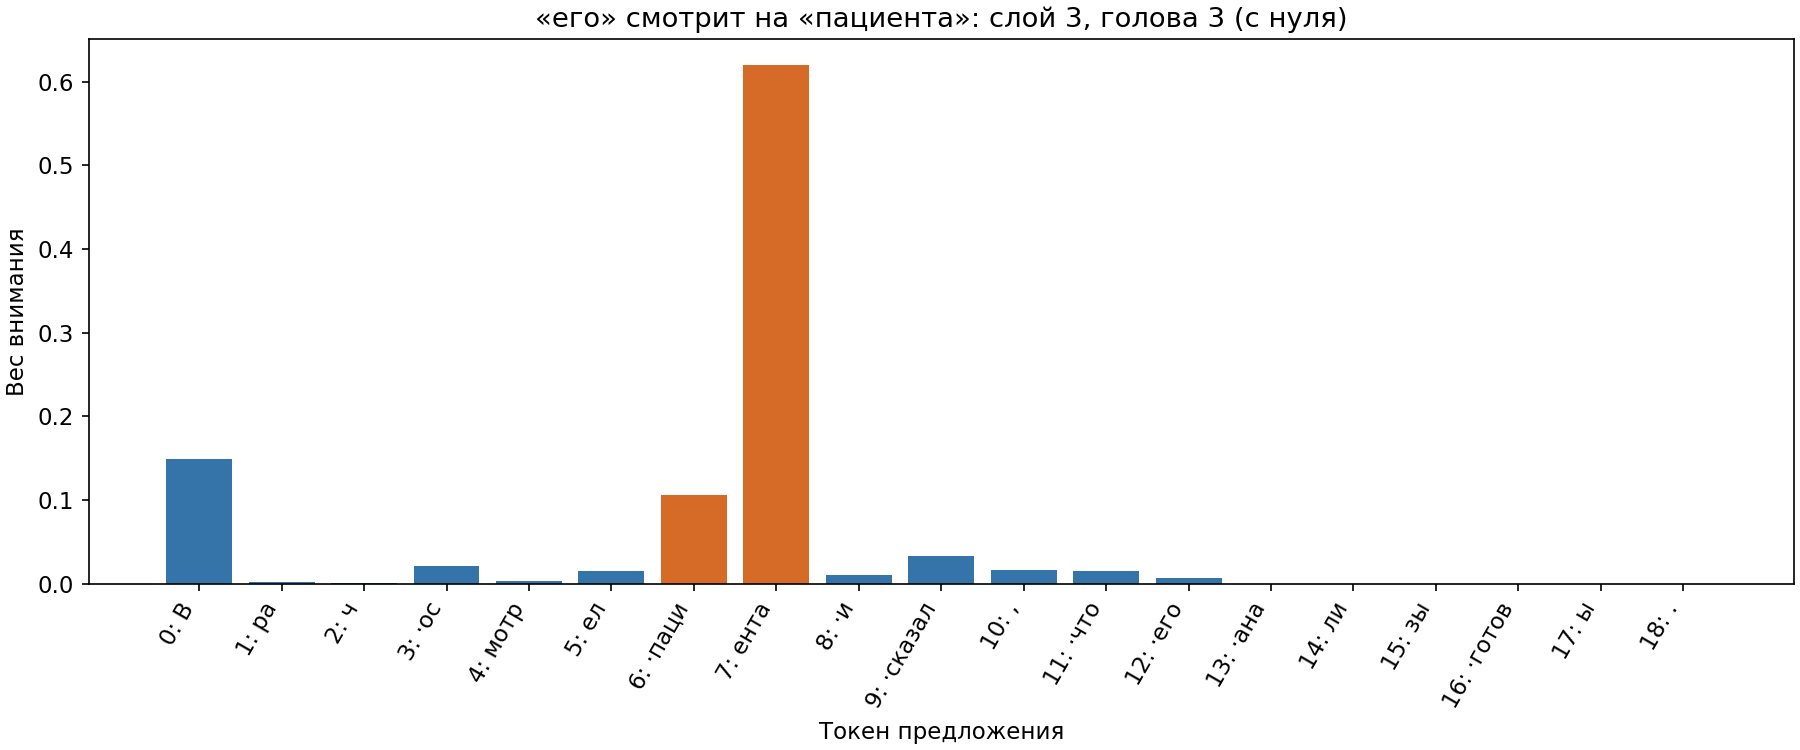

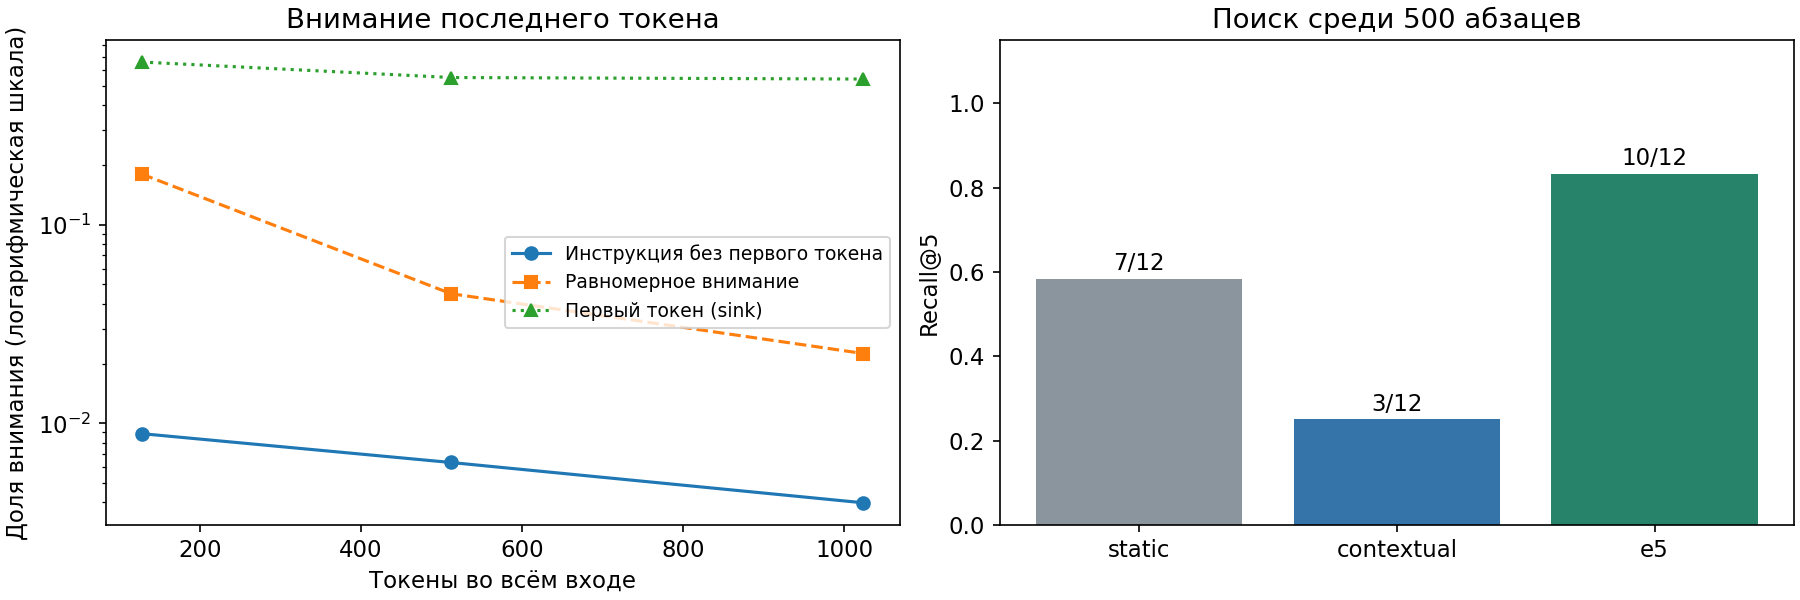

In [20]:
display(Image(filename=str(ART/"attention_map.png")))
display(Image(filename=str(ART/"search_and_dilution.png")))

## 5. Сохраняем результаты
Архив содержит таблицы, графики, векторы и метаданные с хешами. Выполненный ноутбук сохраняется отдельно через Файл > Скачать > Скачать IPYNB.

In [21]:
from google.colab import files
archive=WORK/"lab02-full-results.zip"
with zipfile.ZipFile(archive,"w",zipfile.ZIP_DEFLATED) as z:
    for path in sorted(ART.iterdir()):
        if path.is_file(): z.write(path,"artifacts/"+path.name)
    for name in MANIFEST: z.write(WORK/name,"source/"+name)
print("Готово:",archive.name,archive.stat().st_size,"байт")
files.download(str(archive))

Готово: lab02-full-results.zip 4935444 байт


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>